# Parte Comum — EDA (Wine Quality)
Projeto Final AVD 2026.2 — Grupo 6. Responsável: Arthur Borges

Fonte: Cortez et al. (2009), Modeling wine preferences by data mining from physicochemical properties. Decision Support Systems, 47(4), 547–553. https://doi.org/10.1016/j.dss.2009.05.016

> **Uso de IA:** código marcado com `# [IA]`. Interpretações e decisões de tratamento devem ser escritas pelo grupo.

## Índice deste notebook

- [Pergunta de pesquisa e público-alvo](#secao-0)
- [Configuração](#secao-1)
- [Carga dos dados](#secao-2)
- [1. Análise estrutural](#secao-3)
- [2. Qualidade dos dados](#secao-4)
- [3. Análise distribucional](#secao-5)
- [4. Análise relacional](#secao-6)
- [5. Outliers](#secao-7)
- [6. Tratamento e exportação](#secao-8)
- [7. Síntese da EDA](#secao-9)


Para exportar sem código, na raiz do projeto:
```bash
jupyter nbconvert --to html --no-input notebooks/parte_comum/eda.ipynb --output-dir out/parte_comum/wine_quality --output eda_leitura
```

<a id="secao-0"></a>

## Pergunta de pesquisa e público-alvo

**Base:** Wine Quality combinado. **Classe:** `quality`.

Quais características físico-químicas se associam às notas de qualidade e como se distribuem entre os tipos de vinho?

### 0.1 Definição final da pergunta e público-alvo

A proposta é investigar a relação entre as características físico-químicas e as notas de qualidade dos vinhos tintos e brancos, além de identificar padrões que possam auxiliar a etapa de agrupamento. O público-alvo proposto é composto por profissionais de controle de qualidade e produção de vinhos, interessados em compreender os perfis das amostras analisadas.

<a id="secao-1"></a>

## Configuração

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
candidates = [Path.cwd(), *Path.cwd().parents]
DATA = next((r / 'data/parte_comum/wine_quality/winequality-combined.csv' for r in candidates if (r / 'data/parte_comum/wine_quality/winequality-combined.csv').is_file()), None)
if DATA is None:
    DATA = next((r / 'winequality-combined.csv' for r in candidates if (r / 'winequality-combined.csv').is_file()), None)
if DATA is None:
    raise FileNotFoundError('Coloque winequality-combined.csv em data/parte_comum/wine_quality/')
ROOT = DATA.parents[3] if DATA.parent.name == 'wine_quality' else DATA.parent
OUT = ROOT / 'out/parte_comum/wine_quality'
OUT.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(DATA, sep=';')
coluna_classe = 'quality'
num = df.select_dtypes(include='number').columns.drop(coluna_classe).tolist()

TEMA_ESCURO = False
sns.set_theme(style="darkgrid" if TEMA_ESCURO else "whitegrid")
if TEMA_ESCURO: plt.style.use("dark_background")
plt.rcParams.update({"font.size":12,"figure.dpi":110})
CORES={"red":"#B44B58","white":"#C49A32"}
def salvar(nome):
    plt.tight_layout()
    plt.savefig(OUT / nome,dpi=150,bbox_inches="tight")
    plt.show()
    plt.close()
def tabela(obj,nome,titulo):
    print(titulo)
    display(obj)
    obj.to_csv(OUT/nome)


<a id="secao-2"></a>

## Carga dos dados

In [2]:
df_raw = df.copy()
print(f"{len(df):,} linhas x {df.shape[1]} colunas")
display(df.head())
for c in ["quality","wine_type"]:
    display(df[c].value_counts(dropna=False))

6,497 linhas x 13 colunas


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


quality
6    2836
5    2138
7    1079
4     216
8     193
3      30
9       5
Name: count, dtype: int64

wine_type
white    4898
red      1599
Name: count, dtype: int64

<a id="secao-3"></a>

## 1. Análise estrutural

### 1.1 Visão geral das colunas

In [3]:
# [IA] ChatGPT – apoio à implementação de cálculos, tabelas e gráficos
estrutura=pd.DataFrame({"tipo":df.dtypes.astype(str),"distintos":df.nunique(),"nulos":df.isna().sum(),"exemplo":df.iloc[0]})
tabela(estrutura,"estrutura.csv","Tabela 1.1 — Estrutura")
print("Duplicatas completas:",df.duplicated().sum())
print("Colunas constantes:",df.columns[df.nunique()<=1].tolist())

Tabela 1.1 — Estrutura


,tipo,distintos,nulos,exemplo
fixed acidity,float64,106,0,7.4
volatile acidity,float64,187,0,0.7
citric acid,float64,89,0,0.0
residual sugar,float64,316,0,1.9
chlorides,float64,214,0,0.076
free sulfur dioxide,float64,135,0,11.0
total sulfur dioxide,float64,276,0,34.0
density,float64,998,0,0.9978
pH,float64,108,0,3.51
sulphates,float64,111,0,0.56


Duplicatas completas: 1177
Colunas constantes: []


### 1.2 Estrutura e duplicatas

A base possui 6.497 registros e 13 colunas, sendo 11 atributos físico-químicos numéricos, a nota de qualidade e o tipo de vinho. Não foram encontradas colunas constantes ou valores ausentes. Foram identificadas 1.177 duplicatas completas (18,12% da base). A igualdade entre registros não comprova que se trata de uma mesma amostra, uma vez que não há identificador individual entre as colunas apresentadas.

<a id="secao-4"></a>

## 2. Qualidade dos dados

In [4]:
# [IA] ChatGPT – apoio à implementação de cálculos, tabelas e gráficos
qualidade=pd.DataFrame({"nulos":df.isna().sum(),"percentual_nulos":df.isna().mean()*100,"zeros":(df==0).sum()})
tabela(qualidade,"qualidade_dados.csv","Tabela 2.1 — Ausências e zeros")
tabela(df.groupby("wine_type").apply(lambda g: pd.Series({"linhas":len(g),"duplicatas":g.duplicated().sum()})),"duplicatas_por_tipo.csv","Tabela 2.2 — Duplicatas por tipo")

Tabela 2.1 — Ausências e zeros


,nulos,percentual_nulos,zeros
fixed acidity,0,0.0,0
volatile acidity,0,0.0,0
citric acid,0,0.0,151
residual sugar,0,0.0,0
chlorides,0,0.0,0
free sulfur dioxide,0,0.0,0
total sulfur dioxide,0,0.0,0
density,0,0.0,0
pH,0,0.0,0
sulphates,0,0.0,0


Tabela 2.2 — Duplicatas por tipo


,linhas,duplicatas
wine_type,,
red,1599,240
white,4898,937


### 2.1 Qualidade dos dados

Não foram identificados valores nulos. O atributo `citric acid` apresenta 151 valores iguais a zero, que não devem ser confundidos automaticamente com dados ausentes. Quanto às duplicatas, foram encontradas 240 entre os tintos (15,01%) e 937 entre os brancos (19,13%). A avaliação desses registros deve considerar a possibilidade de medições coincidentes e a influência da repetição sobre o agrupamento.

<a id="secao-5"></a>

## 3. Análise distribucional

### 3.1 Distribuição das notas e dos tipos

Tabela 3.1 — Contagens


quality,3,4,5,6,7,8,9
wine_type,,,,,,,
red,10,53,681,638,199,18,0
white,20,163,1457,2198,880,175,5


Tabela 3.2 — Percentuais por tipo


quality,3,4,5,6,7,8,9
wine_type,,,,,,,
red,0.625391,3.314572,42.589118,39.899937,12.445278,1.125704,0.000000
white,0.408330,3.327889,29.746835,44.875459,17.966517,3.572887,0.102082


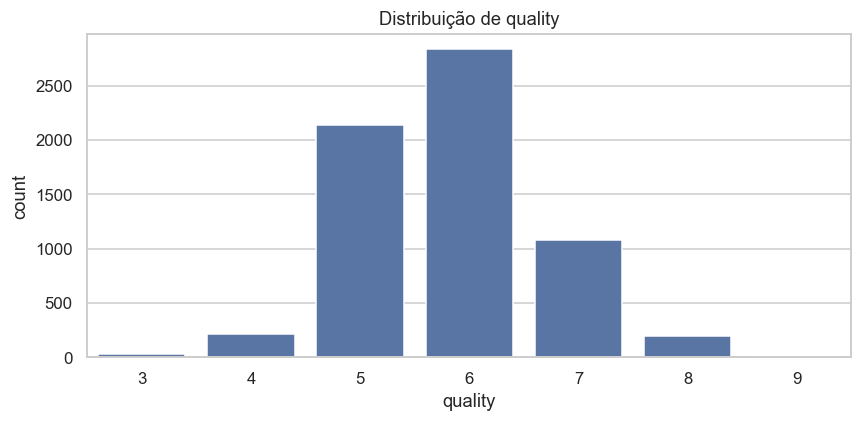

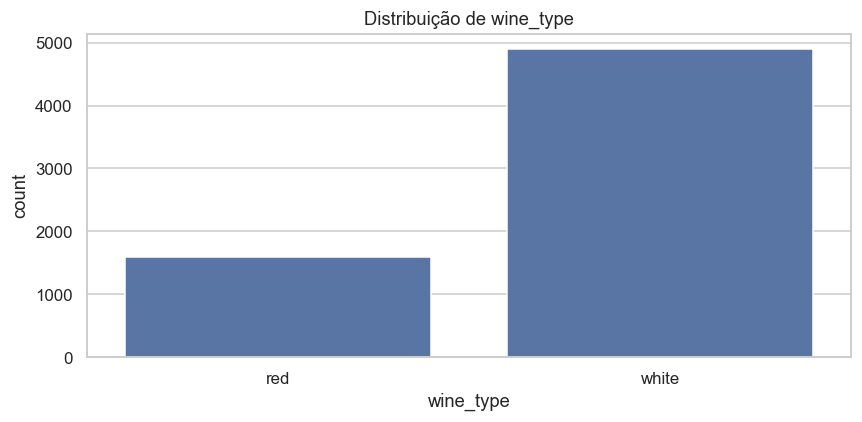

In [5]:
# [IA] ChatGPT – apoio à implementação de cálculos, tabelas e gráficos
tabela(pd.crosstab(df.wine_type,df.quality),"qualidade_por_tipo.csv","Tabela 3.1 — Contagens")
tabela(pd.crosstab(df.wine_type,df.quality,normalize="index")*100,"qualidade_por_tipo_pct.csv","Tabela 3.2 — Percentuais por tipo")
for c in ["quality","wine_type"]:
    plt.figure(figsize=(8,4)); sns.countplot(data=df,x=c); plt.title(f"Distribuição de {c}"); salvar(f"distribuicao_{c}.png")

### 3.2 Distribuições físico-químicas

Tabela 3.3 — Estatísticas descritivas


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000


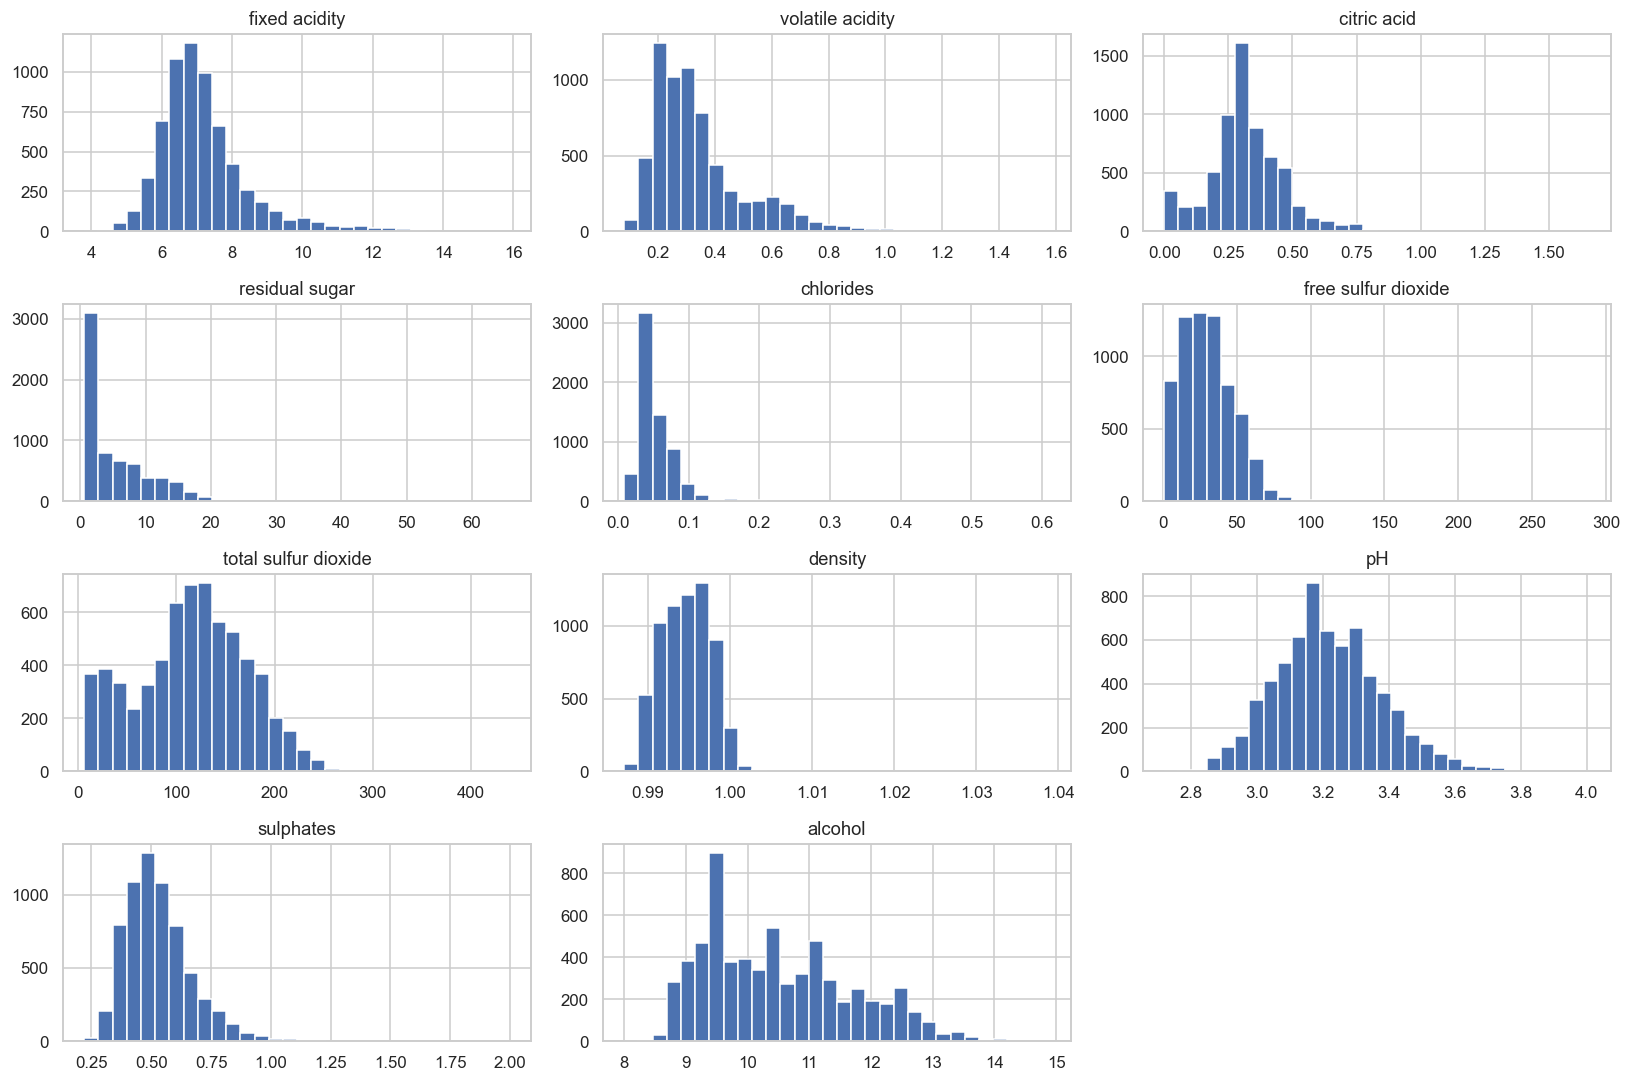

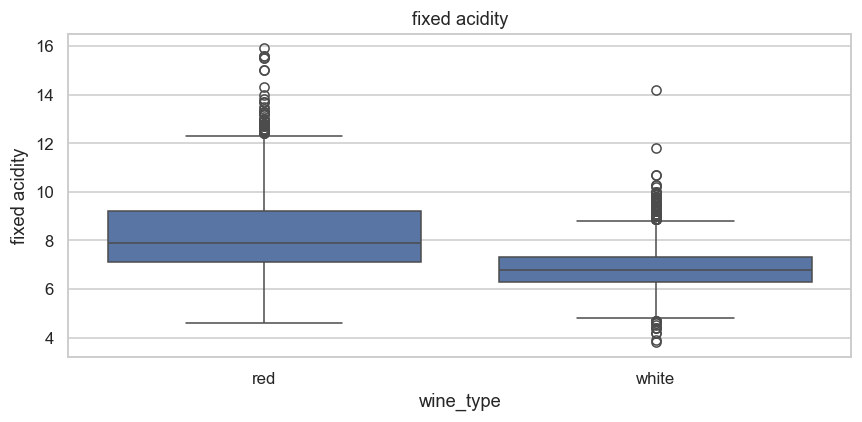

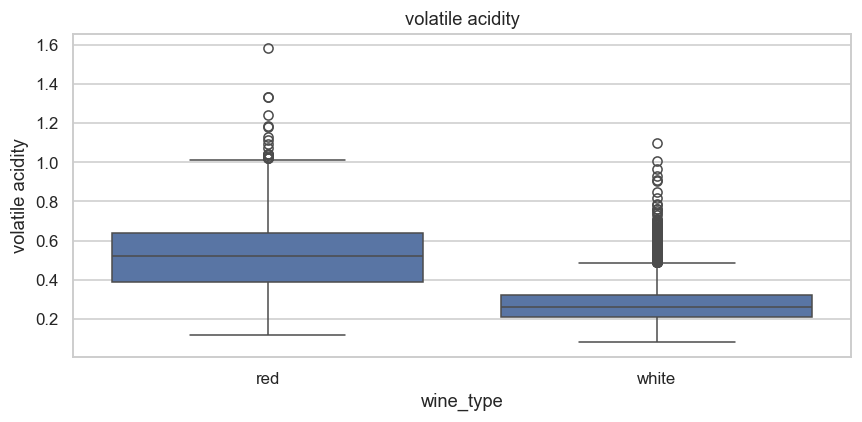

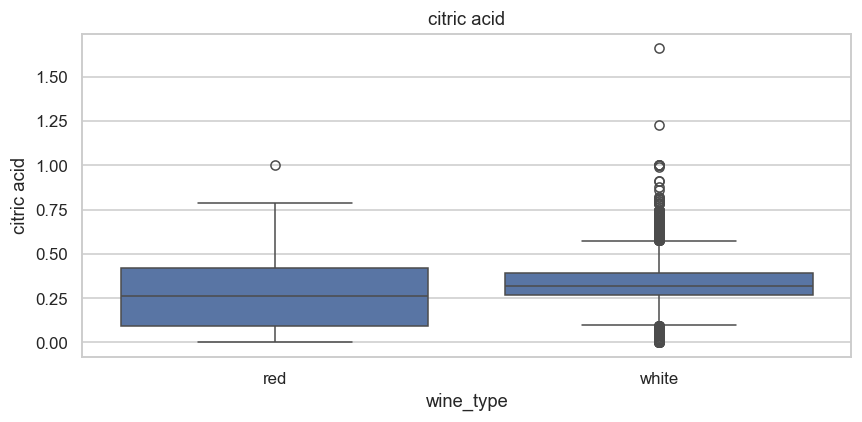

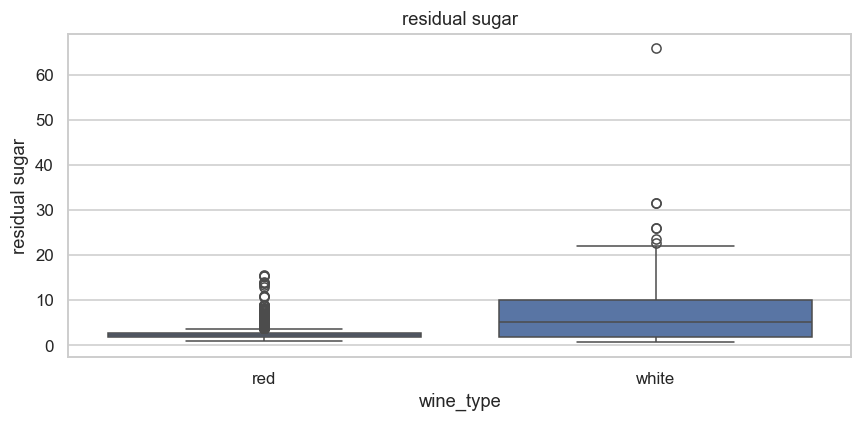

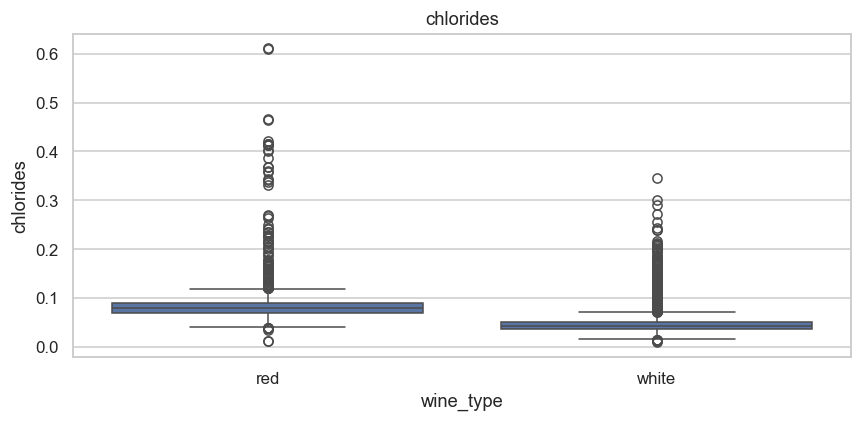

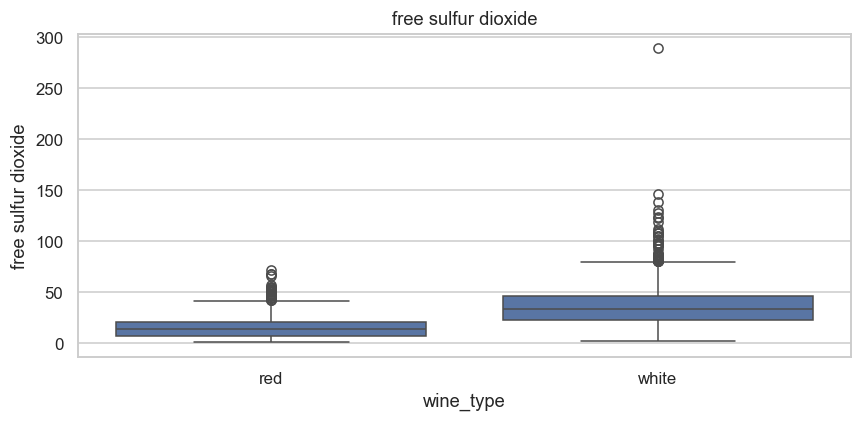

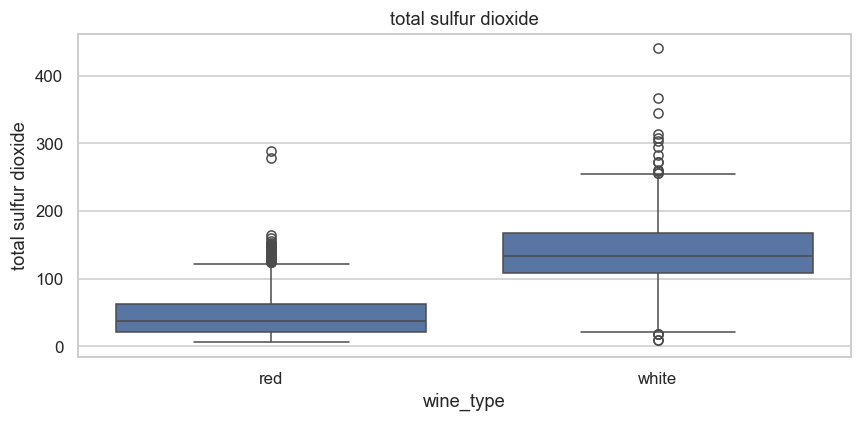

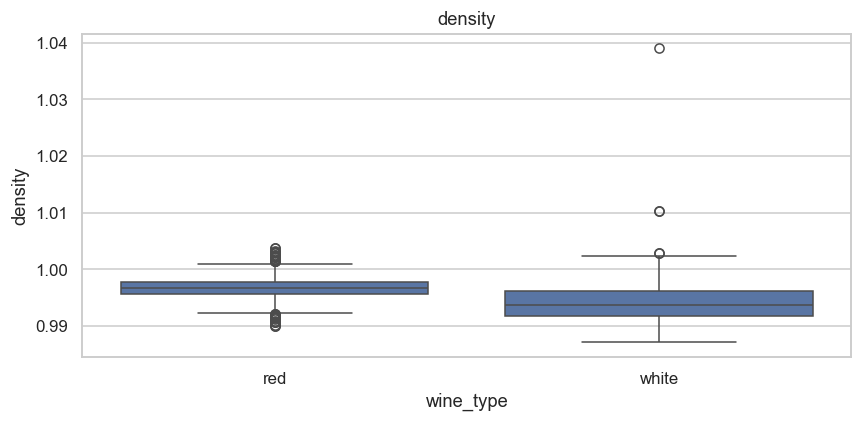

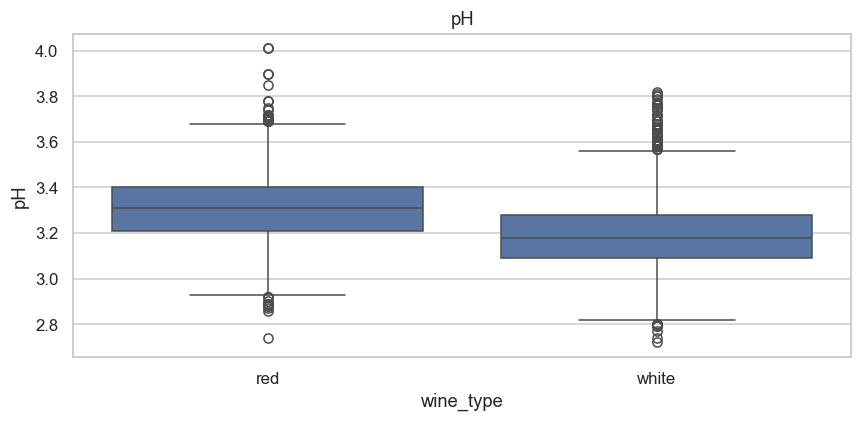

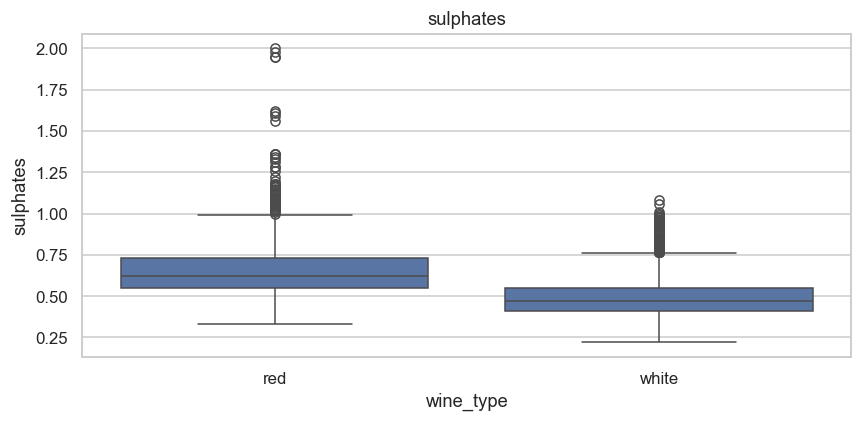

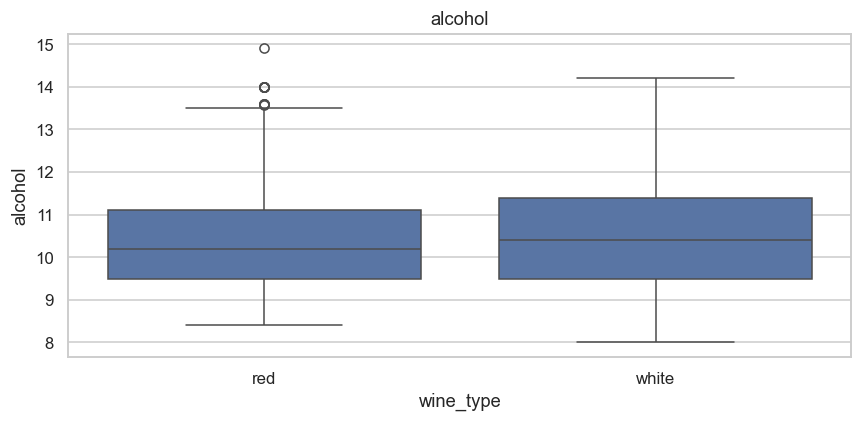

In [6]:
# [IA] ChatGPT – apoio à implementação de cálculos, tabelas e gráficos
tabela(df[num].describe(),"estatisticas_numericas.csv","Tabela 3.3 — Estatísticas descritivas")
df[num].hist(figsize=(15,10),bins=30); salvar("histogramas.png")
for c in num:
    plt.figure(figsize=(8,4)); sns.boxplot(data=df,x="wine_type",y=c); plt.title(c); salvar("box_"+c.replace(" ","_")+".png")

### 3.3 Distribuições e diferenças entre tipos

A distribuição das notas está concentrada nas classes 5 e 6, que representam juntas 76,56% da base. A nota 9 possui apenas cinco registros. Também existe predominância de vinhos brancos (4.898 registros) em relação aos tintos (1.599). Na comparação proporcional, a nota mais frequente dos tintos é 5 (42,59%), enquanto nos brancos é 6 (44,88%). Entre os atributos físico-químicos, o açúcar residual apresenta média de 5,44 e mediana de 3,00, com máximo de 65,80, indicando uma distribuição com valores elevados na cauda superior. As diferenças de escala entre atributos devem ser consideradas na etapa de agrupamento.

<a id="secao-6"></a>

## 4. Análise relacional

### 4.1 Correlações

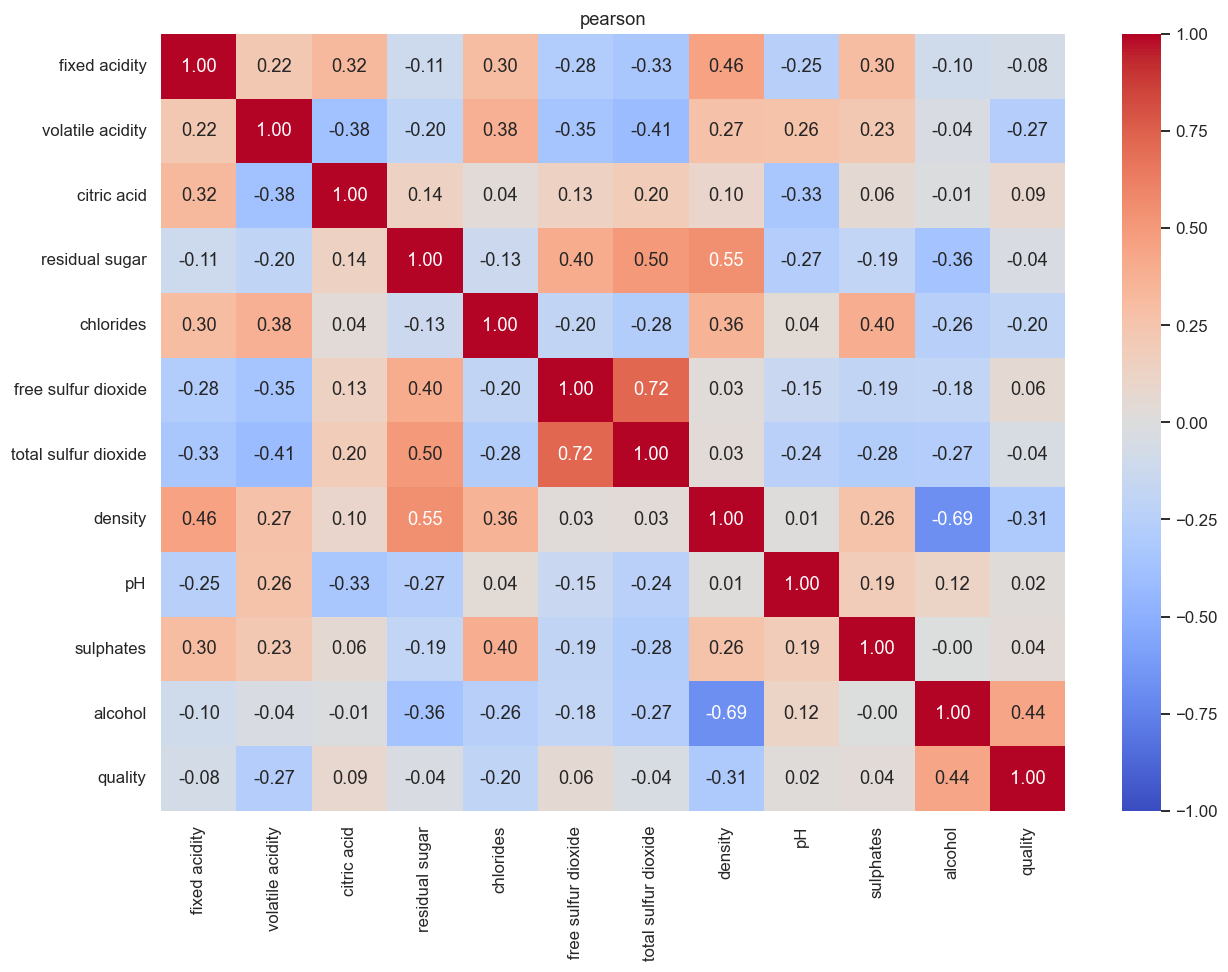

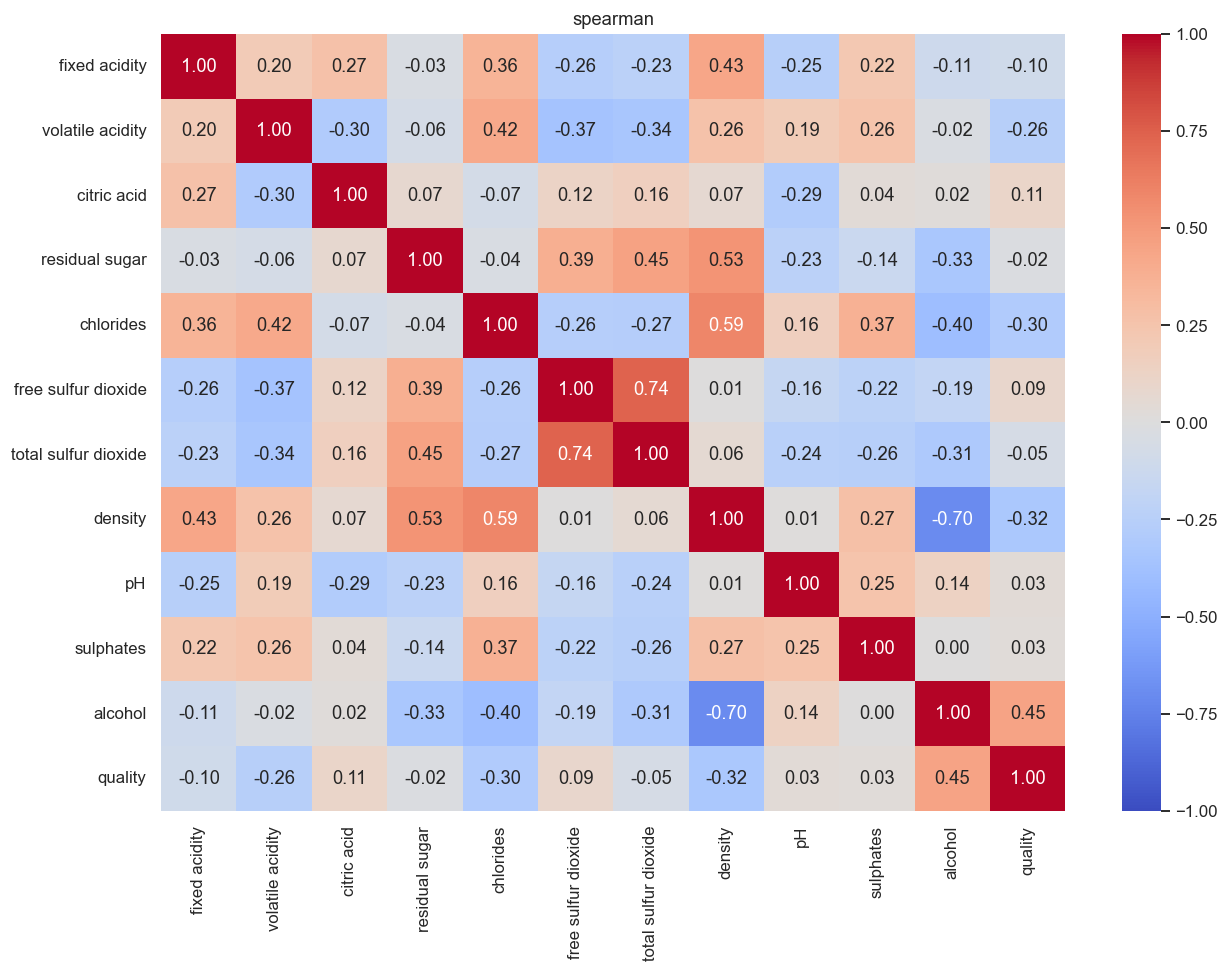

In [7]:
# [IA] ChatGPT – apoio à implementação de cálculos, tabelas e gráficos
for metodo in ["pearson","spearman"]:
    corr=df[num+["quality"]].corr(method=metodo)
    corr.to_csv(OUT/f"correlacao_{metodo}.csv")
    plt.figure(figsize=(12,9)); sns.heatmap(corr,annot=True,fmt=".2f",cmap="coolwarm",center=0,vmin=-1,vmax=1); plt.title(metodo); salvar(f"correlacao_{metodo}.png")

### 4.2 Atributos por nota e tipo

Tabela 4.1 — Atributos por nota


fixed acidity        volatile acidity        citric acid         \
                 mean median             mean median        mean median   
quality                                                                   
3            7.853333   7.45         0.517000  0.415    0.281000   0.33   
4            7.288889   7.00         0.457963  0.380    0.272315   0.26   
5            7.326801   7.10         0.389614  0.330    0.307722   0.30   
6            7.177257   6.90         0.313863  0.270    0.323583   0.31   
7            7.128962   6.90         0.288800  0.270    0.334764   0.32   
8            6.835233   6.80         0.291010  0.280    0.332539   0.32   
9            7.420000   7.10         0.298000  0.270    0.386000   0.36   

        residual sugar        chlorides          ... total sulfur dioxide  \
                  mean median      mean  median  ...                 mean   
quality                                          ...                        
3             5.140000   3.15  0.077033  0.0550  ...           122.033333   
4             4.153704   2.20  0.060056  0.0505  ...           103.432870   
5             5.804116   3.00  0.064666  0.0530  ...           120.839102   
6             5.549753   3.10  0.054157  0.0460  ...           115.410790   
7             4.731696   2.80  0.045272  0.0390  ...           108.498610   
8             5.382902   4.10  0.041124  0.0370  ...           117.518135   
9             4.120000   2.20  0.027400  0.0310  ...           116.000000   

                 density                  pH        sulphates         \
        median      mean    median      mean median      mean median   
quality                                                                
3        102.5  0.995744  0.995900  3.257667  3.245  0.506333  0.505   
4        102.0  0.994833  0.994995  3.231620  3.220  0.505648  0.485   
5        127.0  0.995849  0.996100  3.212189  3.190  0.526403  0.500   
6        117.0  0.994558  0.994700  3.217726  3.210  0.532549  0.510   
7        114.0  0.993126  0.992400  3.228072  3.220  0.547025  0.520   
8        118.0  0.992514  0.991890  3.223212  3.230  0.512487  0.480   
9        119.0  0.991460  0.990300  3.308000  3.280  0.466000  0.460   

           alcohol         
              mean median  
quality                    
3        10.215000  10.15  
4        10.180093  10.00  
5         9.837783   9.60  
6        10.587553  10.50  
7        11.386006  11.40  
8        11.678756  12.00  
9        12.180000  12.50  

[7 rows x 22 columns]

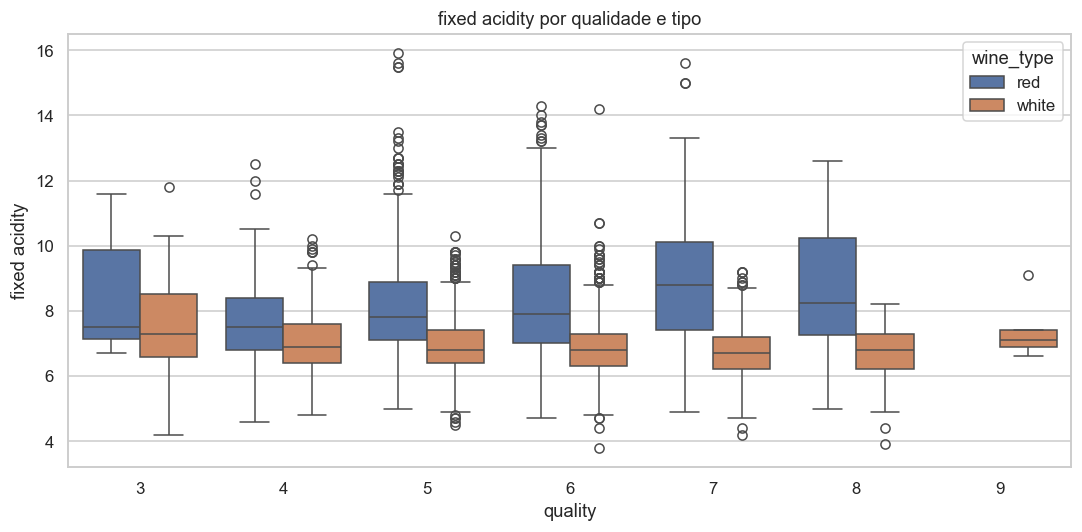

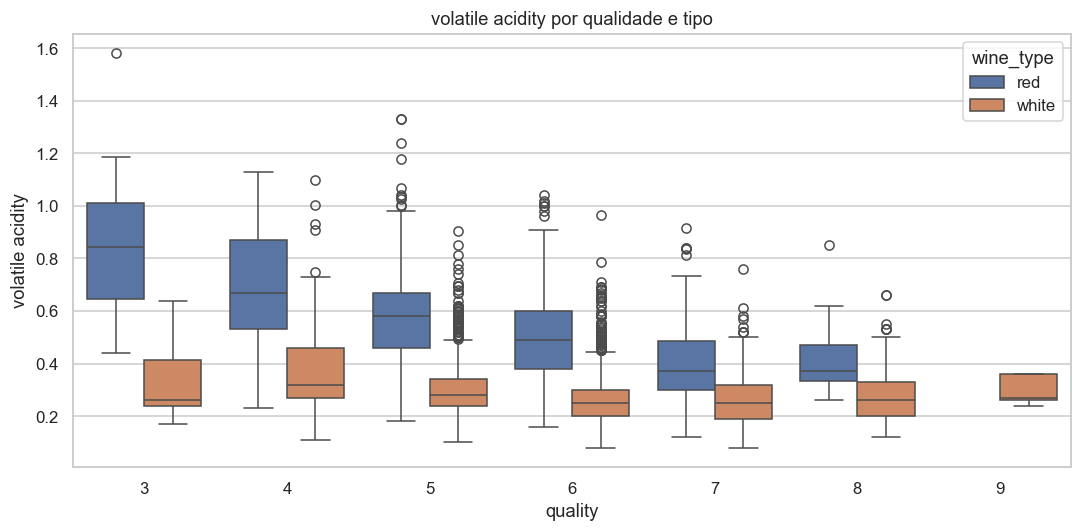

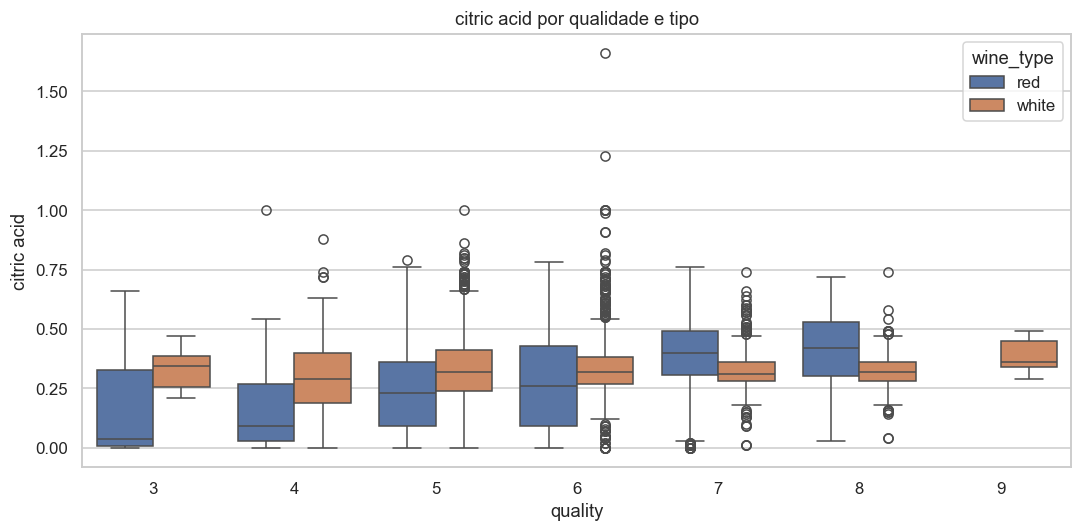

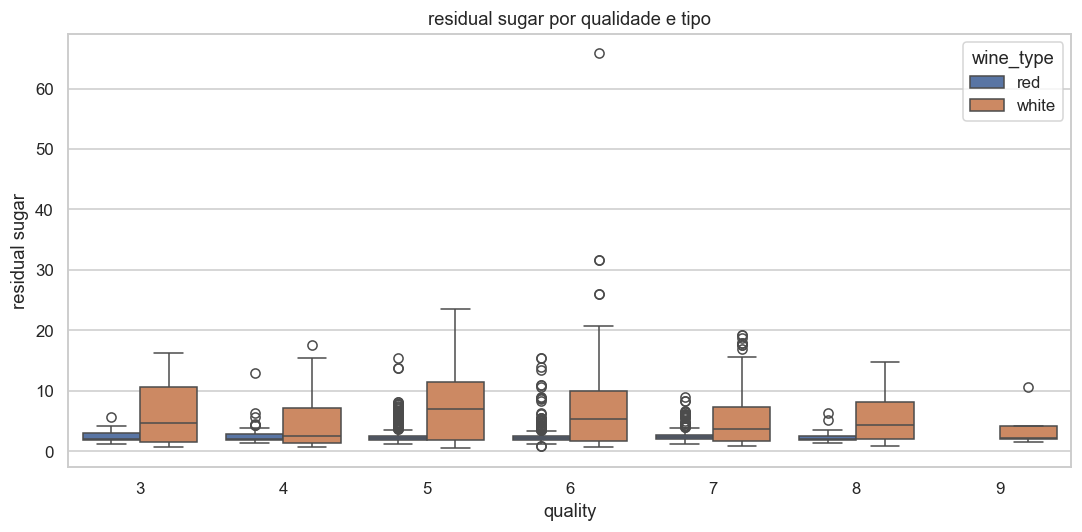

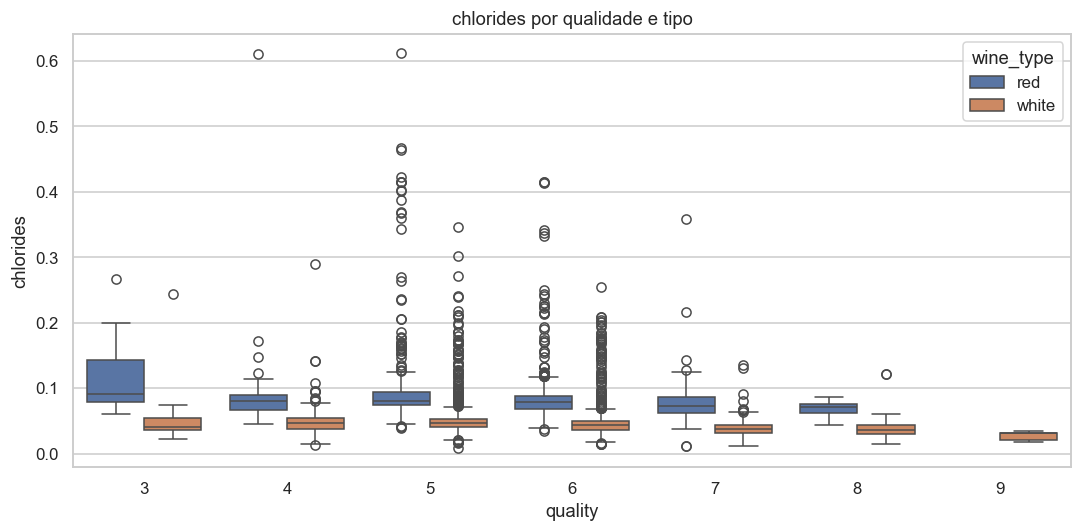

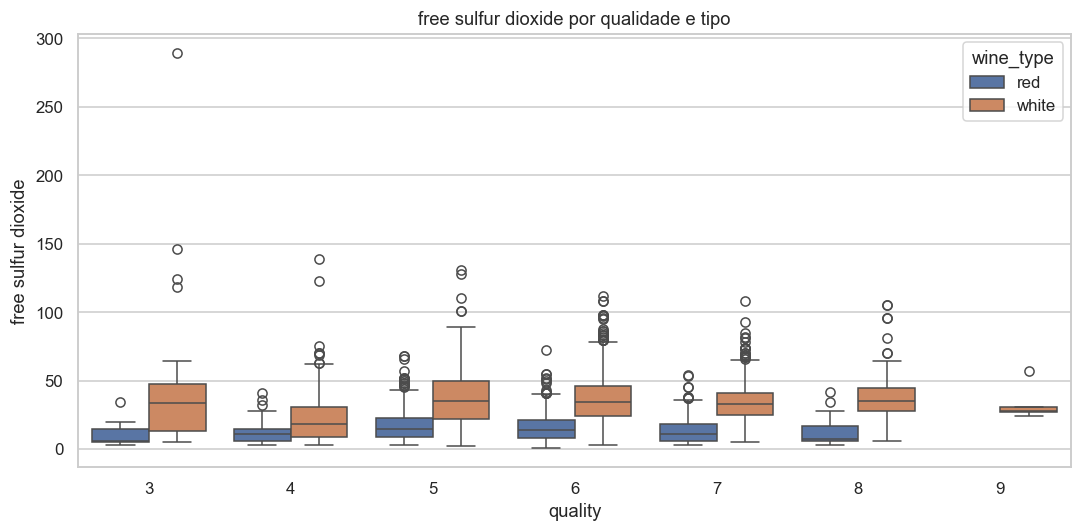

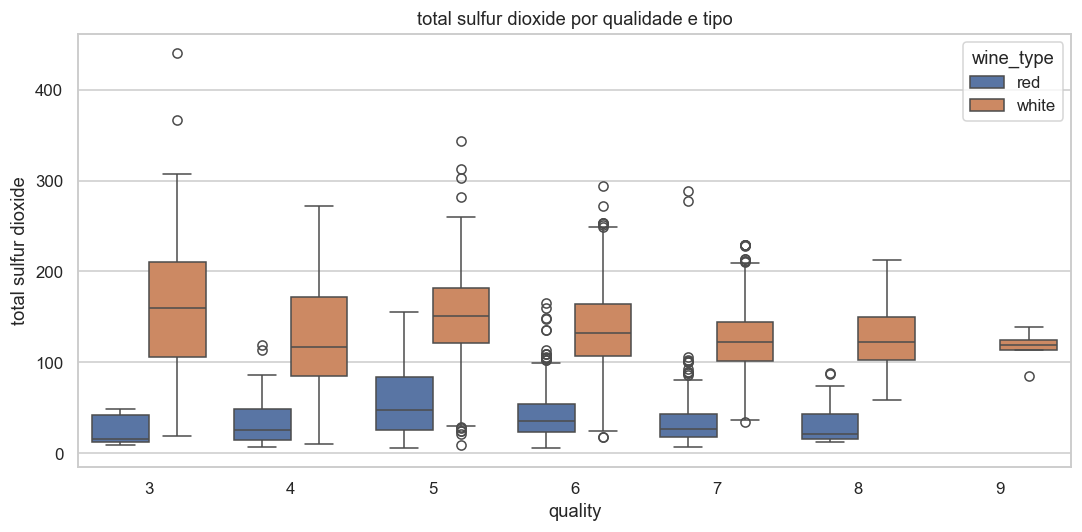

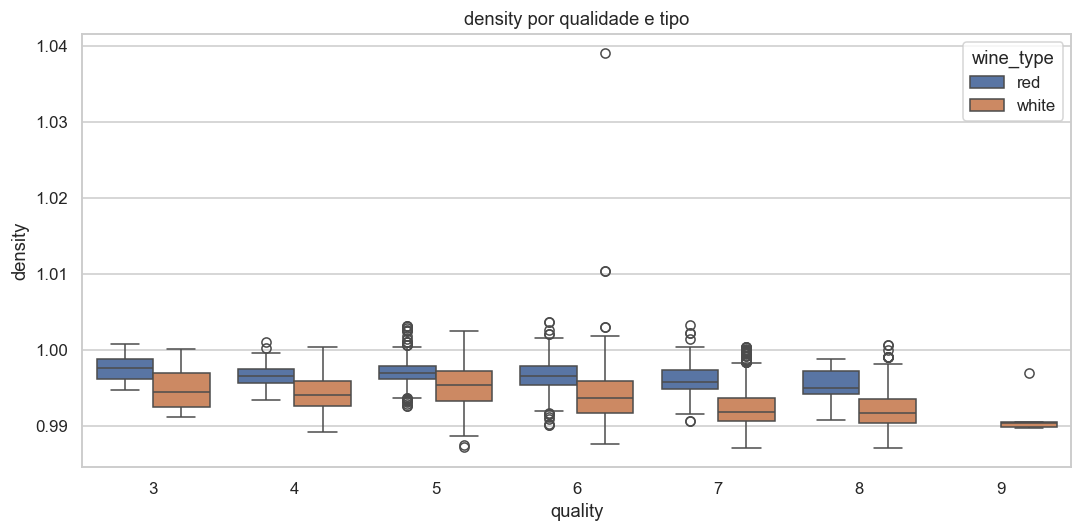

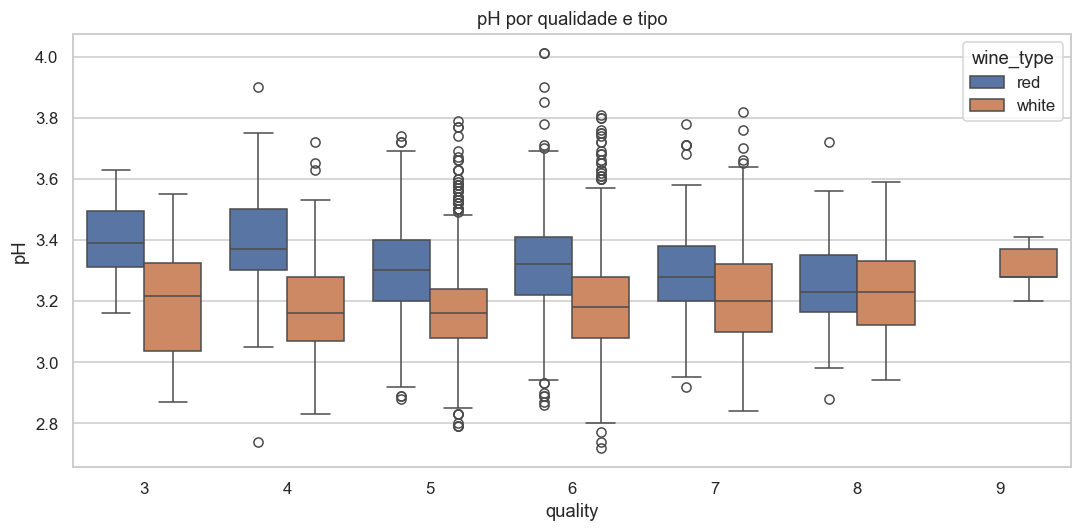

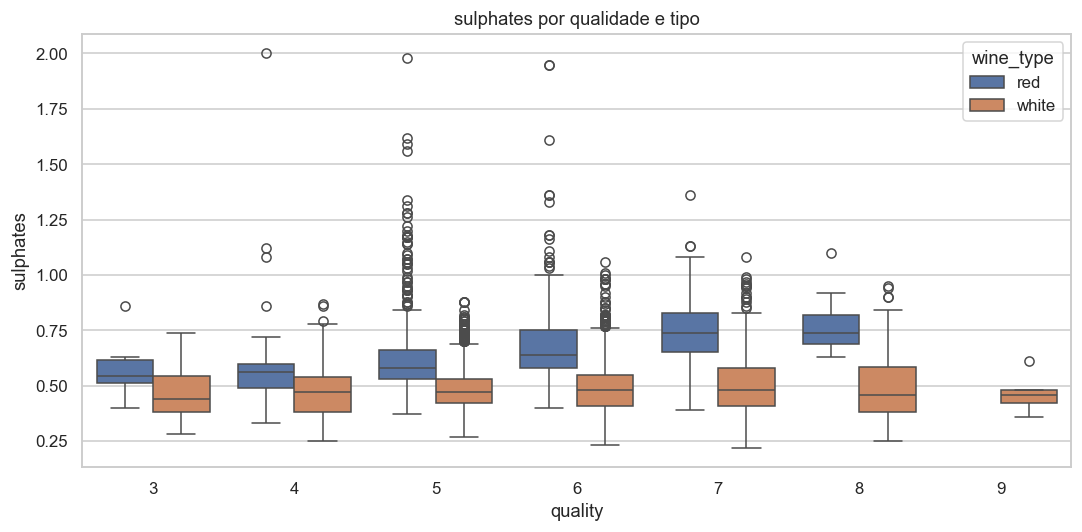

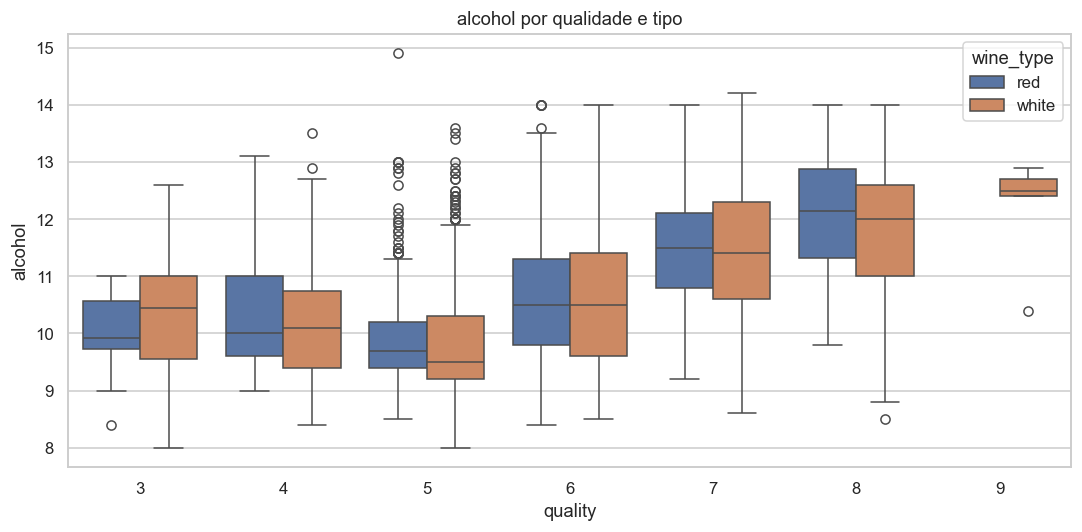

In [8]:
# [IA] ChatGPT – apoio à implementação de cálculos, tabelas e gráficos
tabela(df.groupby("quality")[num].agg(["mean","median"]),"estatisticas_por_qualidade.csv","Tabela 4.1 — Atributos por nota")
for c in num:
    plt.figure(figsize=(10,5)); sns.boxplot(data=df,x="quality",y=c,hue="wine_type"); plt.title(c+" por qualidade e tipo"); salvar("relacao_"+c.replace(" ","_")+".png")

### 4.3 Relações com a qualidade

Na Tabela 4.1, observa-se que a mediana do teor alcoólico aumenta de 9,60 na nota 5 para 10,50 na nota 6 e 11,40 na nota 7. A mediana da densidade diminui de 0,99610 para 0,99470 e 0,99240 nessas mesmas classes. A acidez volátil média também diminui entre as notas 3 e 7, passando de 0,517 para 0,289 aproximadamente. Esses resultados indicam associações na amostra, sem estabelecer causalidade. A interpretação das notas extremas deve considerar sua baixa frequência, especialmente a nota 9. A composição por tipo de vinho também pode influenciar as relações observadas na base combinada.

<a id="secao-7"></a>

## 5. Outliers

In [9]:
# [IA] ChatGPT – apoio à implementação de cálculos, tabelas e gráficos
def iqr_resumo(base):
    q1=base[num].quantile(.25); q3=base[num].quantile(.75); iqr=q3-q1
    lo=q1-1.5*iqr; hi=q3+1.5*iqr
    mask=(base[num]<lo)|(base[num]>hi)
    return pd.DataFrame({"limite_inferior":lo,"limite_superior":hi,"quantidade":mask.sum(),"percentual":mask.mean()*100})
tabela(iqr_resumo(df),"outliers.csv","Tabela 5.1 — IQR global")
for tipo,g in df.groupby("wine_type"):
    tabela(iqr_resumo(g),f"outliers_{tipo}.csv",f"Tabela 5.2 — IQR por tipo: {tipo}")

Tabela 5.1 — IQR global


,limite_inferior,limite_superior,quantidade,percentual
fixed acidity,4.450000,9.650000,357,5.494844
volatile acidity,-0.025000,0.655000,377,5.802678
citric acid,0.040000,0.600000,509,7.834385
residual sugar,-7.650000,17.550000,118,1.816223
chlorides,-0.002500,0.105500,286,4.402032
free sulfur dioxide,-19.000000,77.000000,62,0.954287
total sulfur dioxide,-41.500000,274.500000,10,0.153917
density,0.985365,1.003965,3,0.046175
pH,2.795000,3.635000,73,1.123596
sulphates,0.175000,0.855000,191,2.939818


Tabela 5.2 — IQR por tipo: red


,limite_inferior,limite_superior,quantidade,percentual
fixed acidity,3.950000,12.350000,49,3.064415
volatile acidity,0.015000,1.015000,19,1.188243
citric acid,-0.405000,0.915000,1,0.062539
residual sugar,0.850000,3.650000,155,9.693558
chlorides,0.040000,0.120000,112,7.004378
free sulfur dioxide,-14.000000,42.000000,30,1.876173
total sulfur dioxide,-38.000000,122.000000,55,3.439650
density,0.992248,1.001187,45,2.814259
pH,2.925000,3.685000,35,2.188868
sulphates,0.280000,1.000000,59,3.689806


Tabela 5.2 — IQR por tipo: white


,limite_inferior,limite_superior,quantidade,percentual
fixed acidity,4.800000,8.800000,119,2.429563
volatile acidity,0.045000,0.485000,186,3.797468
citric acid,0.090000,0.570000,270,5.512454
residual sugar,-10.600000,22.200000,7,0.142915
chlorides,0.015000,0.071000,208,4.246631
free sulfur dioxide,-11.500000,80.500000,50,1.020825
total sulfur dioxide,19.500000,255.500000,19,0.387913
density,0.985156,1.002666,5,0.102082
pH,2.805000,3.565000,75,1.531237
sulphates,0.200000,0.760000,124,2.531646


### 5.3 Avaliação dos valores atípicos

Pelo IQR global, o ácido cítrico apresenta a maior proporção de valores sinalizados (509 registros; 7,83%), seguido pela acidez volátil (377; 5,80%) e pela acidez fixa (357; 5,49%). A análise por tipo revela diferenças importantes: o açúcar residual apresenta 155 ocorrências entre tintos (9,69%) e sete entre brancos (0,14%). Isso mostra que os limites globais e por tipo não são equivalentes. Os valores sinalizados não constituem necessariamente erros de medição e as contagens por atributo não representam uma contagem de registros únicos.

<a id="secao-8"></a>

## 6. Tratamento e exportação

Configuração adotada nos dois notebooks da Parte Comum: manter os 6.497 registros (sem remoção das duplicatas nem de outliers) e incluir `wine_type` como indicador binário padronizado no K-Means.

### 6.1 Decisões de tratamento

Na configuração executada, foram mantidos os registros duplicados e os valores sinalizados pelo IQR, sem imputação, pois não há valores nulos explícitos. A Tabela 6.1 confirma a manutenção das 6.497 linhas e 13 colunas. Essa configuração preserva a população original, mas pode atribuir maior peso às observações repetidas e tornar o K-Means sensível a valores extremos.

In [10]:
# [IA] ChatGPT – apoio à implementação de cálculos, tabelas e gráficos
REMOVER_DUPLICATAS=False
df_clean=df_raw.copy()
if REMOVER_DUPLICATAS: df_clean=df_clean.drop_duplicates().copy()
assert df_clean["quality"].notna().all()
tabela(pd.DataFrame({"antes":[len(df_raw),df_raw.shape[1],df_raw.isna().sum().sum(),df_raw.duplicated().sum()],"depois":[len(df_clean),df_clean.shape[1],df_clean.isna().sum().sum(),df_clean.duplicated().sum()]},index=["linhas","colunas","nulos","duplicatas"]),"comparativo_tratamento.csv","Tabela 6.1 — Antes e depois")
df_clean.to_csv(OUT/"winequality_eda_clean.csv",sep=";",index=False)
print("Exportação auxiliar; o K-Means anterior lê o CSV original.")

Tabela 6.1 — Antes e depois


,antes,depois
linhas,6497,6497
colunas,13,13
nulos,0,0
duplicatas,1177,1177


Exportação auxiliar; o K-Means anterior lê o CSV original.


<a id="secao-9"></a>

## 7. Síntese da EDA

### 7.1 Síntese e próximos passos


A análise exploratória identificou uma base sem ausências explícitas, mas com duplicatas, diferenças de escala e distribuição desigual das notas e dos tipos de vinho. As estatísticas por classe evidenciam associações entre a qualidade e atributos como teor alcoólico, densidade e acidez volátil. Para a próxima etapa, recomenda-se padronizar os atributos numéricos e avaliar a influência da inclusão do tipo de vinho. A comparação entre o K livre e o K fixo deverá considerar que as sete notas observadas não garantem a existência de sete agrupamentos naturais. A escolha do K livre e a avaliação dos agrupamentos dependem dos resultados do notebook de K-Means.